
# DS605 — K-Nearest Neighbors (KNN) Regression

## Household Energy Consumption Prediction

### 1. Objective

Investigate the complexity of household energy consumption prediction using K-Nearest Neighbors Regression.

We will compare two feature representations:

- **Model A:** 11 PCA components.
- **Model B:** 6 PCA components + calendar features.

**Target Variable:** Total_Energy (Wh)

### 2. Research Questions

1. How does K affect training and validation error?
2. Does a small K cause overfitting?
3. Does a large K cause underfitting?
4. Which K provides the best generalization?
5. Does adding calendar information improve predictions?

### 3. Mathematical Foundation

For a new observation x, KNN Regression predicts:

$$
\hat{y}(x)=\frac{1}{K}\sum_{i \in N_K(x)} y_i
$$

Euclidean distance:

$$
d(x_i,x_j)=\sqrt{\sum_{m=1}^{p}(x_{im}-x_{jm})^2}
$$

Where:

- K = Number of nearest neighbors
- p = Number of input features
- y = Actual energy consumption
- y_hat = Predicted energy consumption

### 4. Model Complexity

- Small K: High model complexity, low bias, high variance.
- Large K: Low model complexity, high bias, low variance.

### 5. Evaluation Metrics

- MAE — Mean Absolute Error
- MSE — Mean Squared Error
- RMSE — Root Mean Squared Error
- R² — Coefficient of Determination

### 6. Experimental Procedure

1. Load Model A and Model B.
2. Check dataset structure and target variable.
3. Split data chronologically into training, validation, and test sets.
4. Prepare feature scaling without data leakage.
5. Train KNN models using different K values.
6. Plot training and validation error versus K.
7. Select the best K using validation results.
8. Evaluate both models on the untouched test set.
9. Compare results and explain problem complexity.


In [10]:

# ==================================================
# DS605 — KNN Regression
# Required Libraries
# ==================================================

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Feature preprocessing
from sklearn.preprocessing import StandardScaler

# KNN Regression
from sklearn.neighbors import KNeighborsRegressor

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

# Hyperparameter tuning
from sklearn.model_selection import (
    TimeSeriesSplit,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
# Pipeline
from sklearn.pipeline import Pipeline

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

# Reproducibility for any stochastic operations
RANDOM_STATE = 42
from sklearn.decomposition import PCA
print("All KNN libraries imported successfully!")
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV

All KNN libraries imported successfully!


In [2]:

# ==========================================
# Step 1: Load Model A and Model B
# ==========================================

df_A = pd.read_csv("../data/energy_model_A_pca11.csv")
df_B = pd.read_csv("../data/energy_model_B_pca6_calendar.csv")

# Dataset dimensions
print("MODEL A SHAPE:", df_A.shape)
print("MODEL B SHAPE:", df_B.shape)

# Column names
print("\nMODEL A COLUMNS:")
print(df_A.columns.tolist())

print("\nMODEL B COLUMNS:")
print(df_B.columns.tolist())

# Check missing values
print("\nMODEL A MISSING VALUES:", df_A.isnull().sum().sum())
print("MODEL B MISSING VALUES:", df_B.isnull().sum().sum())

# Check duplicate rows
print("\nMODEL A DUPLICATES:", df_A.duplicated().sum())
print("MODEL B DUPLICATES:", df_B.duplicated().sum())

# Preview both datasets
print("\nMODEL A — FIRST 5 ROWS")
display(df_A.head())

print("\nMODEL B — FIRST 5 ROWS")
display(df_B.head())


MODEL A SHAPE: (3289, 14)
MODEL B SHAPE: (3289, 18)

MODEL A COLUMNS:
['date', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'Total_Energy', 'split']

MODEL B COLUMNS:
['date', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'hour_sin', 'hour_cos', 'is_weekend', 'is_afternoon_peak', 'month_2', 'month_3', 'month_4', 'month_5', 'Weekend_Afternoon', 'Total_Energy', 'split']

MODEL A MISSING VALUES: 0
MODEL B MISSING VALUES: 0

MODEL A DUPLICATES: 0
MODEL B DUPLICATES: 0

MODEL A — FIRST 5 ROWS


,date,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,Total_Energy,split
0,2016-01-11 17:00:00,5.110123,1.400306,-0.727908,-0.288922,-1.660293,1.723690,0.153982,-1.227327,-1.108349,-0.197960,0.775331,540,train
1,2016-01-11 18:00:00,5.093709,1.255047,-0.645525,-0.060188,-1.921390,0.655241,-0.143542,-1.387939,-1.002338,-0.038749,0.686973,1370,train
2,2016-01-11 19:00:00,5.703124,2.641273,-0.466049,0.341102,-1.732885,0.508668,-0.237793,-1.192641,-2.147870,-0.750999,0.301881,1190,train
3,2016-01-11 20:00:00,5.363267,2.699256,0.061216,1.835086,-1.645020,0.551409,1.138031,-1.231681,-1.244798,-0.418894,0.246485,960,train
4,2016-01-11 21:00:00,4.532671,2.561363,0.192938,1.772744,-1.557283,0.699563,0.570903,-1.148758,-0.840036,-0.178371,0.370830,760,train



MODEL B — FIRST 5 ROWS


,date,PC1,PC2,PC3,PC4,PC5,PC6,hour_sin,hour_cos,is_weekend,is_afternoon_peak,month_2,month_3,month_4,month_5,Weekend_Afternoon,Total_Energy,split
0,2016-01-11 17:00:00,-2.385360,1.332462,-0.822393,0.229846,0.179091,-0.308249,-0.965926,-2.588190e-01,0,1,0,0,0,0,0,540,train
1,2016-01-11 18:00:00,-2.389230,1.254058,-0.803186,0.132570,0.137984,-0.281298,-1.000000,-1.836970e-16,0,1,0,0,0,0,0,1370,train
2,2016-01-11 19:00:00,-2.475669,2.257678,-0.787061,-0.109231,0.748326,-0.734700,-0.965926,2.588190e-01,0,0,0,0,0,0,0,1190,train
3,2016-01-11 20:00:00,-2.323473,2.501608,-0.720584,-0.667954,0.243962,-0.106355,-0.866025,5.000000e-01,0,0,0,0,0,0,0,960,train
4,2016-01-11 21:00:00,-1.883592,2.138435,-0.463353,-0.658371,0.053692,-0.082442,-0.707107,7.071068e-01,0,0,0,0,0,0,0,760,train


In [3]:

# =============================================
# Step 2: Verify Existing Data Splits
# =============================================

for name, df in [("Model A", df_A), ("Model B", df_B)]:

    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")

    print("\nSplit Counts:")
    print(df["split"].value_counts())

    print("\nDate Range by Split:")
    print(
        df.groupby("split")["date"]
        .agg(["min", "max", "count"])
    )

    print("\nChronological Order:",
          pd.to_datetime(df["date"]).is_monotonic_increasing)

# Confirm corresponding timestamps and partitions
print("\nSame Dates:",
      df_A["date"].equals(df_B["date"]))

print("Same Split Assignments:",
      df_A["split"].equals(df_B["split"]))



Model A

Split Counts:
split
train    2631
test      658
Name: count, dtype: int64

Date Range by Split:
                       min                  max  count
split                                                 
test   2016-04-30 08:00:00  2016-05-27 17:00:00    658
train  2016-01-11 17:00:00  2016-04-30 07:00:00   2631

Chronological Order: True

Model B

Split Counts:
split
train    2631
test      658
Name: count, dtype: int64

Date Range by Split:
                       min                  max  count
split                                                 
test   2016-04-30 08:00:00  2016-05-27 17:00:00    658
train  2016-01-11 17:00:00  2016-04-30 07:00:00   2631

Chronological Order: True

Same Dates: True
Same Split Assignments: True


In [4]:

# ==========================================
# Step 3: Prepare X and y for Both Models
# ==========================================

target = "Total_Energy"
exclude = ["date", "split", target]

features_A = [c for c in df_A.columns if c not in exclude]
features_B = [c for c in df_B.columns if c not in exclude]

# Existing chronological partitions
train_A = df_A[df_A["split"] == "train"]
test_A = df_A[df_A["split"] == "test"]

train_B = df_B[df_B["split"] == "train"]
test_B = df_B[df_B["split"] == "test"]

# Model A
X_train_A = train_A[features_A]
y_train_A = train_A[target]

X_test_A = test_A[features_A]
y_test_A = test_A[target]

# Model B
X_train_B = train_B[features_B]
y_train_B = train_B[target]

X_test_B = test_B[features_B]
y_test_B = test_B[target]

print("MODEL A")
print("Training:", X_train_A.shape)
print("Testing:", X_test_A.shape)
print("Features:", features_A)

print("\nMODEL B")
print("Training:", X_train_B.shape)
print("Testing:", X_test_B.shape)
print("Features:", features_B)

print("\nTargets identical:",
      y_train_A.reset_index(drop=True).equals(
          y_train_B.reset_index(drop=True)
      ))


MODEL A
Training: (2631, 11)
Testing: (658, 11)
Features: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11']

MODEL B
Training: (2631, 15)
Testing: (658, 15)
Features: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'hour_sin', 'hour_cos', 'is_weekend', 'is_afternoon_peak', 'month_2', 'month_3', 'month_4', 'month_5', 'Weekend_Afternoon']

Targets identical: True



## Step 4: KNN Model Complexity Analysis

### Objective

Investigate the effect of K on KNN regression performance
for Model A and Model B.

### Research Question

How does changing the number of nearest neighbors affect
training and validation prediction error?

### Hypotheses

- Small K may cause overfitting.
- Large K may cause underfitting.
- An intermediate K may provide better generalization.

### Methodology

1. Test multiple K values.
2. Use time-series cross-validation within the training set.
3. Standardize features separately within each training fold.
4. Calculate training RMSE and validation RMSE.
5. Identify the K with the lowest average validation RMSE.
6. Compare the complexity curves for Model A and Model B.

The final test set will not be used to select K.

### Evaluation Metric

Root Mean Squared Error:

$$
RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
$$

Lower RMSE indicates better predictive performance.


In [5]:

# ==========================================
# Step 4: KNN Complexity Analysis
# Model A and Model B
# ==========================================

k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]

tscv = TimeSeriesSplit(n_splits=5)

results = []

for model_name, X, y in [
    ("Model A", X_train_A, y_train_A),
    ("Model B", X_train_B, y_train_B)
]:

    for k in k_values:

        train_errors = []
        val_errors = []

        for train_idx, val_idx in tscv.split(X):

            X_tr = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_tr = y.iloc[train_idx]
            y_val = y.iloc[val_idx]

            # Scaling is fitted only on each training fold
            knn = Pipeline([
                ("scaler", StandardScaler()),
                ("model", KNeighborsRegressor(
                    n_neighbors=k
                ))
            ])

            knn.fit(X_tr, y_tr)

            train_pred = knn.predict(X_tr)
            val_pred = knn.predict(X_val)

            train_errors.append(
                root_mean_squared_error(y_tr, train_pred)
            )

            val_errors.append(
                root_mean_squared_error(y_val, val_pred)
            )

        results.append({
            "Model": model_name,
            "K": k,
            "Train_RMSE": np.mean(train_errors),
            "Validation_RMSE": np.mean(val_errors)
        })

knn_results = pd.DataFrame(results)

display(knn_results)


,Model,K,Train_RMSE,Validation_RMSE
0,Model A,1,0.000000,645.529515
1,Model A,2,269.593447,568.513554
2,Model A,3,317.957966,539.445391
3,Model A,5,366.537916,503.896107
4,Model A,7,394.620573,486.501640
5,Model A,10,419.489490,478.597979
6,Model A,15,446.766891,469.975174
7,Model A,20,459.857953,465.086870
8,Model A,30,475.297465,463.880623
9,Model A,50,487.892343,463.857447



## Step 5: KNN Model Complexity Visualization

### Objective

Visualize the relationship between K, training RMSE and
validation RMSE for both models.

### Interpretation

- Low training RMSE and high validation RMSE indicate overfitting.
- High training and validation errors may indicate underfitting.
- Low validation RMSE indicates better generalization.

### Research Question

At which K does the model transition from overfitting
toward better generalization?

We will compare Model A and Model B separately.


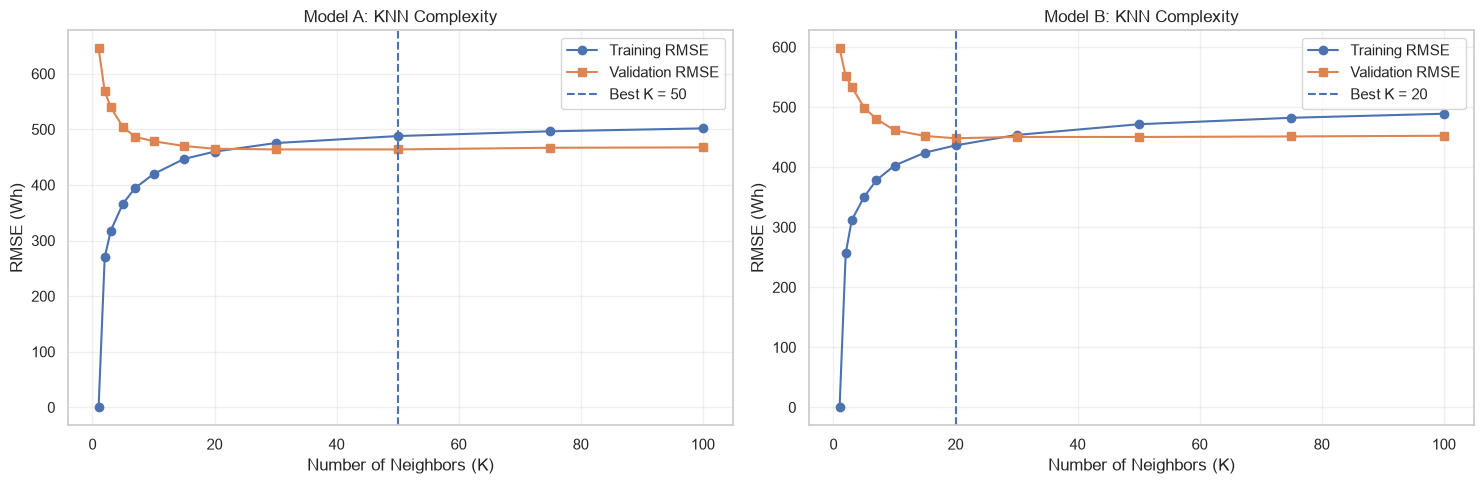

In [6]:

# ==========================================
# Step 5: Plot KNN Complexity Curves
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, model_name in zip(axes, ["Model A", "Model B"]):

    data = knn_results[
        knn_results["Model"] == model_name
    ]

    ax.plot(
        data["K"], data["Train_RMSE"],
        marker="o", label="Training RMSE"
    )

    ax.plot(
        data["K"], data["Validation_RMSE"],
        marker="s", label="Validation RMSE"
    )

    best = data.loc[data["Validation_RMSE"].idxmin()]

    ax.axvline(
        best["K"], linestyle="--",
        label=f"Best K = {int(best['K'])}"
    )

    ax.set_title(f"{model_name}: KNN Complexity")
    ax.set_xlabel("Number of Neighbors (K)")
    ax.set_ylabel("RMSE (Wh)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



## Step 6: Baseline Comparison

### Objective

Determine whether KNN Regression provides better predictions
than a simple mean-based baseline.

### Baseline Model

The baseline always predicts the average energy consumption
of the training observations.

$$
\hat{y}_{baseline} = \frac{1}{n}\sum_{i=1}^{n}y_i
$$

### Research Question

Does KNN learn useful relationships between input features
and household energy consumption?

### Method

Compare baseline and KNN validation RMSE using the same
time-series cross-validation folds.

The test set remains untouched.


In [7]:

# ==========================================
# Step 6: Mean Baseline vs KNN
# ==========================================

baseline_results = []

for model_name, X, y, best_k in [
    ("Model A", X_train_A, y_train_A, 50),
    ("Model B", X_train_B, y_train_B, 20)
]:

    baseline_errors = []
    knn_errors = []

    for train_idx, val_idx in tscv.split(X):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        # Baseline prediction
        baseline_pred = np.full(
            len(y_val), y_tr.mean()
        )

        baseline_errors.append(
            root_mean_squared_error(y_val, baseline_pred)
        )

        # KNN prediction
        knn = Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor(
                n_neighbors=best_k
            ))
        ])

        knn.fit(X_tr, y_tr)

        knn_pred = knn.predict(X_val)

        knn_errors.append(
            root_mean_squared_error(y_val, knn_pred)
        )

    baseline_rmse = np.mean(baseline_errors)
    knn_rmse = np.mean(knn_errors)

    improvement = (
        (baseline_rmse - knn_rmse) / baseline_rmse
    ) * 100

    baseline_results.append({
        "Model": model_name,
        "Baseline_RMSE": baseline_rmse,
        "KNN_RMSE": knn_rmse,
        "Improvement_%": improvement
    })

baseline_df = pd.DataFrame(baseline_results)

display(baseline_df.round(2))


,Model,Baseline_RMSE,KNN_RMSE,Improvement_%
0,Model A,498.55,463.86,6.96
1,Model B,498.55,448.05,10.13



## Step 7: KNN Cross-Validation Stability Analysis

### Objective

Evaluate whether KNN performs consistently across different
time periods of our household energy dataset.

### Method

- Use 5-fold expanding-window TimeSeriesSplit.
- Model A: K = 50
- Model B: K = 20
- Standardize features within each training fold.
- Calculate validation RMSE for each fold.
- Compare mean and standard deviation of validation RMSE.

### Mathematical Foundation

Mean RMSE:

$$
\overline{RMSE}=\frac{1}{5}\sum_{i=1}^{5}RMSE_i
$$

Standard Deviation:

$$
s=\sqrt{\frac{\sum_{i=1}^{5}(RMSE_i-\overline{RMSE})^2}{4}}
$$

A smaller RMSE standard deviation indicates more consistent
validation error across time periods.

### Research Question

Does Model B produce more stable predictions across
different validation periods than Model A?


In [8]:

# ==========================================
# Step 7: Cross-Validation Stability
# ==========================================

fold_results = []

for model_name, X, y, best_k in [
    ("Model A", X_train_A, y_train_A, 50),
    ("Model B", X_train_B, y_train_B, 20)
]:

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X), start=1
    ):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        knn = Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor(
                n_neighbors=best_k
            ))
        ])

        knn.fit(X_tr, y_tr)

        predictions = knn.predict(X_val)

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Validation_RMSE": root_mean_squared_error(
                y_val, predictions
            ),
            "Train_Size": len(train_idx),
            "Validation_Size": len(val_idx)
        })

fold_df = pd.DataFrame(fold_results)

print("RMSE FOR EACH FOLD:")
display(fold_df.round(2))

print("\nCROSS-VALIDATION SUMMARY:")
cv_summary = (
    fold_df.groupby("Model")["Validation_RMSE"]
    .agg(["mean", "std", "min", "max"])
)

display(cv_summary.round(2))


RMSE FOR EACH FOLD:


,Model,Fold,Validation_RMSE,Train_Size,Validation_Size
0,Model A,1,503.32,441,438
1,Model A,2,445.58,879,438
2,Model A,3,467.21,1317,438
3,Model A,4,474.22,1755,438
4,Model A,5,428.95,2193,438
5,Model B,1,495.29,441,438
6,Model B,2,405.56,879,438
7,Model B,3,471.65,1317,438
8,Model B,4,458.81,1755,438
9,Model B,5,408.96,2193,438



CROSS-VALIDATION SUMMARY:


,mean,std,min,max
Model,,,,
Model A,463.86,28.41,428.95,503.32
Model B,448.05,39.49,405.56,495.29


In [14]:
room_scaler = StandardScaler()
pca_11 = PCA(n_components=11, svd_solver="full")

In [15]:
knn_A = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=11, svd_solver="full")),
    ("knn", KNeighborsRegressor(n_neighbors=50))
])

In [16]:

# Step 9: Inspect original feature-engineered dataset

df_original = pd.read_csv(
    "../data/energy_1hour_fe_ready.csv"
)

print("Dataset Shape:", df_original.shape)

print("\nColumns:")
print(df_original.columns.tolist())

print("\nFirst 5 Rows:")
display(df_original.head())


Dataset Shape: (3289, 43)

Columns:
['date', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'RH_1', 'RH_2', 'RH_3', 'RH_4', 'RH_5', 'RH_6', 'RH_7', 'RH_8', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'day_of_week', 'is_weekend', 'Floor_1_Temp', 'Floor_2_Temp', 'Floor_1_Humidity', 'Floor_2_Humidity', 'hour_sin', 'hour_cos', 'is_afternoon_peak', 'month_2', 'month_3', 'month_4', 'month_5', 'Floor_1_Temp_Change', 'Floor_2_Temp_Change', 'Both_Floors_Warming', 'Weekend_Afternoon', 'Total_Energy']

First 5 Rows:


,date,T1,T2,T3,T4,T5,T6,T7,T8,T9,RH_1,RH_2,RH_3,RH_4,RH_5,RH_6,RH_7,RH_8,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,day_of_week,is_weekend,Floor_1_Temp,Floor_2_Temp,Floor_1_Humidity,Floor_2_Humidity,hour_sin,hour_cos,is_afternoon_peak,month_2,month_3,month_4,month_5,Floor_1_Temp_Change,Floor_2_Temp_Change,Both_Floors_Warming,Weekend_Afternoon,Total_Energy
0,2016-01-11 17:00:00,19.890000,19.200000,19.790000,18.932778,17.166667,6.586667,17.177778,18.150000,17.016667,46.502778,44.626528,44.897778,45.738750,55.116667,84.260000,41.400000,48.710556,45.446667,6.308333,733.750000,92.000000,6.166667,53.416667,5.050000,0,False,19.626667,17.688778,45.342361,47.282528,-0.965926,-2.588190e-01,1,0,0,0,0,0.000000,0.000000,0,0,540
1,2016-01-11 18:00:00,19.897778,19.268889,19.770000,18.908333,17.111111,6.180000,17.229583,18.094444,16.981667,45.879028,44.438889,44.863333,46.066667,54.977778,87.204444,42.046806,48.597222,45.290000,5.941667,734.266667,91.583333,5.416667,40.000000,4.658333,0,False,19.645556,17.665028,45.060417,47.395694,-1.000000,-1.836970e-16,1,0,0,0,0,0.018889,-0.023750,0,0,1370
2,2016-01-11 19:00:00,20.495556,19.925556,20.052222,18.969444,17.136111,5.857361,17.850000,18.156111,16.902222,52.805556,46.061667,47.227361,47.815556,55.869861,88.131389,45.017778,49.213333,45.311389,6.000000,734.791667,89.750000,6.000000,40.000000,4.391667,0,False,20.157778,17.802778,48.698194,48.645583,-0.965926,2.588190e-01,0,0,0,0,0,0.512222,0.137750,1,0,1190
3,2016-01-11 20:00:00,20.961111,20.251111,20.213889,19.190833,17.615556,5.469444,17.632222,18.773333,16.890000,48.453333,45.632639,47.268889,49.227917,74.027778,86.933889,42.920000,50.195556,45.118889,6.000000,735.283333,87.583333,6.000000,40.000000,4.016667,0,False,20.475370,18.020389,47.118287,52.298028,-0.866025,5.000000e-01,0,0,0,0,0,0.317593,0.217611,1,0,960
4,2016-01-11 21:00:00,21.311667,20.587778,20.373333,19.425556,18.427222,5.578889,17.863611,19.153333,16.890000,45.768333,44.961111,46.164444,47.918889,69.037778,86.129444,43.618333,49.542222,44.807778,5.833333,735.566667,87.416667,6.000000,40.000000,3.816667,0,False,20.757593,18.351944,45.631296,50.985000,-0.707107,7.071068e-01,0,0,0,0,0,0.282222,0.331556,1,0,760


In [17]:

# ==========================================
# Step 10: Prepare Original Features
# ==========================================

# Exact Model A features from PCA notebook
room_columns = (
    [f"T{i}" for i in range(1, 10)]
    + [f"RH_{i}" for i in range(1, 10)]
    + [
        "T_out", "Press_mm_hg", "RH_out",
        "Windspeed", "Visibility", "Tdewpoint"
    ]
)

# Exact Model B environmental features
floor_weather_columns = [
    "Floor_1_Temp",
    "Floor_2_Temp",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "T_out",
    "RH_out"
]

# Model B calendar features
calendar_columns = [
    "hour_sin",
    "hour_cos",
    "is_weekend",
    "is_afternoon_peak",
    "month_2",
    "month_3",
    "month_4",
    "month_5",
    "Weekend_Afternoon"
]

# Ensure original rows match both saved PCA datasets
assert df_original["date"].equals(df_A["date"])
assert df_original["date"].equals(df_B["date"])

# Preserve original train/test assignments
train_mask = df_A["split"] == "train"
test_mask = df_A["split"] == "test"

# Original training data
original_train = df_original.loc[train_mask].copy()
original_test = df_original.loc[test_mask].copy()

# Model A inputs
X_original_A = original_train[room_columns]

# Model B inputs
X_original_B = original_train[
    floor_weather_columns + calendar_columns
].astype(float)

# Shared target
y_original = original_train["Total_Energy"]

print("MODEL A:", X_original_A.shape)
print("MODEL B:", X_original_B.shape)
print("TARGET:", y_original.shape)

print("\nTraining observations:",
      len(original_train))

print("Reserved test observations:",
      len(original_test))

print("\nTargets match saved PCA datasets:",
      y_original.reset_index(drop=True).equals(
          y_train_A.reset_index(drop=True)
      ))


MODEL A: (2631, 24)
MODEL B: (2631, 15)
TARGET: (2631,)

Training observations: 2631
Reserved test observations: 658

Targets match saved PCA datasets: True


In [19]:

# ================================================
# Step 11: Leakage-Free KNN Cross-Validation
# ================================================

k_values = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]

cv = TimeSeriesSplit(n_splits=5)

# Model A: 24 features -> PCA 11 -> KNN
pipeline_A = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=11, svd_solver="full")),
    ("final_scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

# Model B: PCA for environmental features only
preprocessor_B = ColumnTransformer([
    ("environment", Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=6, svd_solver="full"))
    ]), floor_weather_columns),

    ("calendar", "passthrough", calendar_columns)
])

pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("final_scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

results_corrected = []

for model_name, X, pipeline in [
    ("Model A", X_original_A, pipeline_A),
    ("Model B", X_original_B, pipeline_B)
]:

    for k in k_values:

        train_rmse = []
        val_rmse = []

        pipeline.set_params(knn__n_neighbors=k)

        for train_idx, val_idx in cv.split(X):

            X_tr = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_tr = y_original.iloc[train_idx]
            y_val = y_original.iloc[val_idx]

            # Refit scaling, PCA and KNN for every fold
            pipeline.fit(X_tr, y_tr)

            pred_train = pipeline.predict(X_tr)
            pred_val = pipeline.predict(X_val)

            train_rmse.append(
                root_mean_squared_error(y_tr, pred_train)
            )

            val_rmse.append(
                root_mean_squared_error(y_val, pred_val)
            )

        results_corrected.append({
            "Model": model_name,
            "K": k,
            "Train_RMSE": np.mean(train_rmse),
            "Validation_RMSE": np.mean(val_rmse),
            "Validation_STD": np.std(val_rmse, ddof=1)
        })

knn_corrected = pd.DataFrame(results_corrected)

print("LEAKAGE-FREE KNN RESULTS:")
display(knn_corrected.round(2))

print("\nBEST K FOR EACH MODEL:")
best_knn = (
    knn_corrected
    .loc[knn_corrected.groupby("Model")[
        "Validation_RMSE"
    ].idxmin()]
)

display(best_knn.round(2))


LEAKAGE-FREE KNN RESULTS:


,Model,K,Train_RMSE,Validation_RMSE,Validation_STD
0,Model A,1,0.00,657.29,82.15
1,Model A,2,262.99,579.99,61.43
2,Model A,3,314.30,539.25,61.23
3,Model A,5,370.05,504.14,48.88
4,Model A,7,395.23,488.01,43.39
5,Model A,10,420.07,479.84,41.32
6,Model A,15,443.80,471.46,36.26
7,Model A,20,457.49,468.56,38.32
8,Model A,30,475.13,466.13,37.13
9,Model A,50,489.51,467.35,39.99



BEST K FOR EACH MODEL:


,Model,K,Train_RMSE,Validation_RMSE,Validation_STD
8,Model A,30,475.13,466.13,37.13
19,Model B,20,438.16,450.68,43.19


In [20]:

# ==========================================
# Step 12: Final KNN Test Evaluation
# ==========================================

# Original test features
X_original_test_A = original_test[room_columns]

X_original_test_B = original_test[
    floor_weather_columns + calendar_columns
].astype(float)

y_original_test = original_test["Total_Energy"]

# Fit selected models on entire training period
pipeline_A.set_params(knn__n_neighbors=30)
pipeline_B.set_params(knn__n_neighbors=20)

pipeline_A.fit(X_original_A, y_original)
pipeline_B.fit(X_original_B, y_original)

# Predict on untouched test period
pred_A = pipeline_A.predict(X_original_test_A)
pred_B = pipeline_B.predict(X_original_test_B)

test_results = []

for name, predictions in [
    ("Model A", pred_A),
    ("Model B", pred_B)
]:

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_original_test, predictions
        ),
        "MSE": mean_squared_error(
            y_original_test, predictions
        ),
        "RMSE": root_mean_squared_error(
            y_original_test, predictions
        ),
        "R2": r2_score(
            y_original_test, predictions
        )
    })

knn_test_results = pd.DataFrame(test_results)

print("FINAL KNN TEST RESULTS:")
display(knn_test_results.round(3))


FINAL KNN TEST RESULTS:


,Model,MAE,MSE,RMSE,R2
0,Model A,269.984,166137.296,407.599,0.086
1,Model B,282.002,181309.299,425.804,0.002


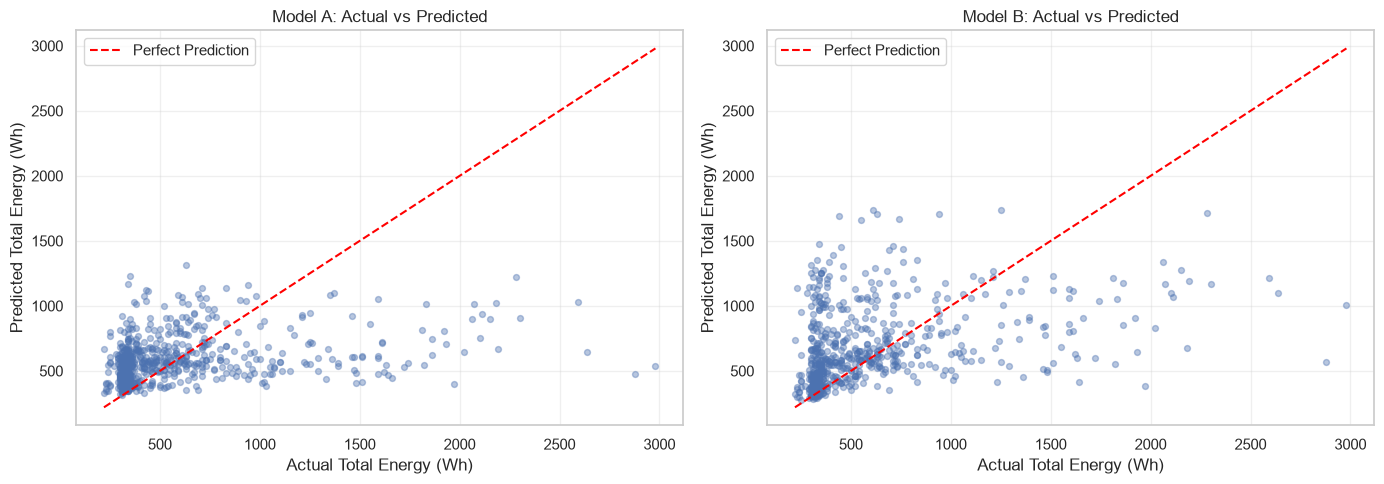

In [21]:

# ==========================================
# Step 13: Actual vs Predicted Energy
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

actual = y_original_test.to_numpy()

for ax, name, predictions in [
    (axes[0], "Model A", pred_A),
    (axes[1], "Model B", pred_B)
]:

    ax.scatter(
        actual, predictions,
        alpha=0.4, s=18
    )

    limits = [
        min(actual.min(), predictions.min()),
        max(actual.max(), predictions.max())
    ]

    ax.plot(
        limits, limits,
        linestyle="--",
        color="red",
        label="Perfect Prediction"
    )

    ax.set_xlabel("Actual Total Energy (Wh)")
    ax.set_ylabel("Predicted Total Energy (Wh)")
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [22]:

# ==========================================
# Step 14: Error Analysis by Energy Level
# ==========================================

# Thresholds based ONLY on training targets
q33, q67 = y_original.quantile([1/3, 2/3])

print(f"Low/Medium threshold: {q33:.2f} Wh")
print(f"Medium/High threshold: {q67:.2f} Wh")

actual = y_original_test.to_numpy()

energy_groups = pd.cut(
    actual,
    bins=[-np.inf, q33, q67, np.inf],
    labels=["Low", "Medium", "High"]
)

error_results = []

for model_name, predictions in [
    ("Model A", pred_A),
    ("Model B", pred_B)
]:

    for group in ["Low", "Medium", "High"]:

        mask = np.asarray(energy_groups == group)

        y_true = actual[mask]
        y_pred = predictions[mask]

        error_results.append({
            "Model": model_name,
            "Energy_Level": group,
            "Observations": len(y_true),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": root_mean_squared_error(y_true, y_pred),
            "Mean_Residual": np.mean(y_true - y_pred)
        })

energy_error_df = pd.DataFrame(error_results)

display(energy_error_df.round(2))


Low/Medium threshold: 320.00 Wh
Medium/High threshold: 573.33 Wh


,Model,Energy_Level,Observations,MAE,RMSE,Mean_Residual
0,Model A,Low,139,192.72,225.61,-192.72
1,Model A,Medium,302,174.03,228.74,-161.25
2,Model A,High,217,453.02,631.15,350.47
3,Model B,Low,139,213.51,328.21,-211.95
4,Model B,Medium,302,230.88,346.89,-217.10
5,Model B,High,217,397.02,559.74,212.81


In [23]:
# Model B environmental inputs
kernel_B_features = [
    "Floor_1_Temp",
    "Floor_2_Temp",
    "Floor_1_Humidity",
    "Floor_2_Humidity",
    "T_out",
    "RH_out"
]

X_kernel_B_train = df_kernel.loc[
    kernel_train_mask, kernel_B_features
].copy()

X_kernel_B_test = df_kernel.loc[
    kernel_test_mask, kernel_B_features
].copy()

# Fit scaling on training observations only
kernel_B_scaler = StandardScaler()

X_kernel_B_train_scaled = kernel_B_scaler.fit_transform(
    X_kernel_B_train
)

X_kernel_B_test_scaled = kernel_B_scaler.transform(
    X_kernel_B_test
)

print("Training shape:", X_kernel_B_train_scaled.shape)
print("Testing shape:", X_kernel_B_test_scaled.shape)

display(X_kernel_B_train.head())

NameError: name 'df_kernel' is not defined

In [1]:

# All libraries — import only once
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load both PCA datasets
data_dir = Path("../data")

df_a = pd.read_csv(data_dir / "energy_model_A_pca11.csv")
df_b = pd.read_csv(data_dir / "energy_model_B_pca6_calendar.csv")

# Remove all calendar features from Model B
b_columns = (
    ["date"]
    + [f"PC{i}" for i in range(1, 7)]
    + ["Total_Energy", "split"]
)
df_b = df_b[b_columns].copy()

# Save PCA-only Model B
df_b.to_csv(data_dir / "energy_model_B_pca6_only.csv", index=False)

datasets = {}

for name, df, n_pcs in [
    ("A", df_a, 11),
    ("B", df_b, 6)
]:
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    features = [f"PC{i}" for i in range(1, n_pcs + 1)]
    split = df["split"].astype(str).str.strip().str.lower()

    train_mask = split == "train"
    test_mask = split == "test"

    assert (train_mask | test_mask).all(), "Unexpected split labels"
    assert train_mask.sum() > 0 and test_mask.sum() > 0

    X_train = df.loc[train_mask, features]
    X_test = df.loc[test_mask, features]
    y_train = df.loc[train_mask, "Total_Energy"]
    y_test = df.loc[test_mask, "Total_Energy"]

    datasets[name] = (X_train, X_test, y_train, y_test)

    print(
        f"Model {name}:",
        f"Train={X_train.shape}, Test={X_test.shape}"
    )

# Store results for algorithm comparisons
results = []
trained_models = {}

# Common evaluation function
def evaluate_algorithm(algorithm_name, pipeline):
    output = []

    for model_name, data in datasets.items():
        X_train, X_test, y_train, y_test = data

        model = clone(pipeline)
        model.fit(X_train, y_train)

        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        cv_scores = cross_val_score(
            clone(pipeline),
            X_train,
            y_train,
            cv=TimeSeriesSplit(n_splits=5),
            scoring="neg_root_mean_squared_error",
            n_jobs=1
        )

        row = {
            "Algorithm": algorithm_name,
            "Model": model_name,
            "Train_RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
            "CV_RMSE": -cv_scores.mean(),
            "Test_MAE": mean_absolute_error(y_test, test_pred),
            "Test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
            "Test_R2": r2_score(y_test, test_pred)
        }

        results.append(row)
        output.append(row)
        trained_models[(algorithm_name, model_name)] = model

    display(pd.DataFrame(output).round(3))


Model A: Train=(2631, 11), Test=(658, 11)
Model B: Train=(2631, 6), Test=(658, 6)


In [2]:

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(
        n_neighbors=7,
        weights="distance",
        metric="minkowski",
        p=2
    ))
])

evaluate_algorithm("KNN", knn_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,KNN,A,0.0,487.468,275.387,442.167,-0.076
1,KNN,B,0.0,500.397,345.694,499.540,-0.373


In [3]:

linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("polynomial", PolynomialFeatures(
        degree=1,
        include_bias=False
    )),
    ("linear", LinearRegression())
])

evaluate_algorithm("Linear Regression", linear_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,A,469.349,465.446,272.022,395.884,0.138
1,Linear Regression,B,482.789,472.113,326.837,419.379,0.032


In [4]:

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        C=100,
        epsilon=50,
        gamma="scale"
    ))
])

evaluate_algorithm("SVR", svr_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,SVR,A,456.113,473.451,238.890,415.428,0.050
1,SVR,B,471.892,473.157,262.335,406.781,0.089


In [5]:

tree_pipeline = Pipeline([
    ("tree", DecisionTreeRegressor(
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

evaluate_algorithm("Decision Tree", tree_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Decision Tree,A,359.620,568.888,320.200,489.765,-0.320
1,Decision Tree,B,381.906,596.858,395.648,598.111,-0.968


In [6]:

bagging_pipeline = Pipeline([
    ("bagging", BaggingRegressor(
        estimator=DecisionTreeRegressor(
            max_depth=8,
            min_samples_leaf=5,
            random_state=42
        ),
        n_estimators=100,
        max_samples=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

evaluate_algorithm("Bagging", bagging_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Bagging,A,355.160,471.226,331.428,432.718,-0.030
1,Bagging,B,379.519,490.307,341.382,439.382,-0.062


In [7]:

gb_pipeline = Pipeline([
    ("gradient_boosting", GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    ))
])

evaluate_algorithm("Gradient Boosting", gb_pipeline)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Gradient Boosting,A,379.838,476.78,433.182,540.897,-0.610
1,Gradient Boosting,B,402.325,507.10,401.459,504.173,-0.399


In [8]:

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by=["Model", "Test_RMSE"]
).reset_index(drop=True)

display(comparison_df.round(3))

# Save results
comparison_df.to_csv(
    data_dir / "pca_only_algorithm_comparison.csv",
    index=False
)


,Algorithm,Model,Train_RMSE,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,A,469.349,465.446,272.022,395.884,0.138
1,SVR,A,456.113,473.451,238.890,415.428,0.050
2,Bagging,A,355.160,471.226,331.428,432.718,-0.030
3,KNN,A,0.000,487.468,275.387,442.167,-0.076
4,Decision Tree,A,359.620,568.888,320.200,489.765,-0.320
5,Gradient Boosting,A,379.838,476.780,433.182,540.897,-0.610
6,SVR,B,471.892,473.157,262.335,406.781,0.089
7,Linear Regression,B,482.789,472.113,326.837,419.379,0.032
8,Bagging,B,379.519,490.307,341.382,439.382,-0.062
9,KNN,B,0.000,500.397,345.694,499.540,-0.373


In [11]:

# Add these to the initial imports cell:
# from sklearn.linear_model import Ridge
# from sklearn.model_selection import GridSearchCV

# Model A only (11 PCA features)
X_train, X_test, y_train, y_test = datasets["A"]

# Ridge Regression Pipeline
ridge_pipeline = Pipeline([
    ("polynomial", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Hyperparameter search space
param_grid = {
    "polynomial__degree": [1, 2],
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
    return_train_score=True
)

# Fit using training data only
grid_search.fit(X_train, y_train)

# Best configuration
best_model = grid_search.best_estimator_

print("Best Hyperparameters:", grid_search.best_params_)
print("Best CV RMSE:", round(-grid_search.best_score_, 3))

# Evaluate on held-out test data
y_pred = best_model.predict(X_test)

print("\nTest Results")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R2:", round(r2_score(y_test, y_pred), 3))

# Display all hyperparameter combinations
cv_results = pd.DataFrame(grid_search.cv_results_)

cv_results["CV_RMSE"] = -cv_results["mean_test_score"]

display(
    cv_results[
        [
            "param_polynomial__degree",
            "param_ridge__alpha",
            "CV_RMSE",
            "std_test_score"
        ]
    ].sort_values("CV_RMSE").round(3)
)


Best Hyperparameters: {'polynomial__degree': 1, 'ridge__alpha': 100}
Best CV RMSE: 463.113

Test Results
MAE: 270.97
RMSE: 395.387
R2: 0.14


,param_polynomial__degree,param_ridge__alpha,CV_RMSE,std_test_score
4,1,100.00,463.113,31.777
3,1,10.00,465.051,33.342
2,1,1.00,465.402,33.703
1,1,0.10,465.441,33.746
0,1,0.01,465.446,33.751
11,2,1000.00,467.229,33.512
5,1,1000.00,467.495,35.253
10,2,100.00,494.378,70.908
9,2,10.00,577.623,195.950
8,2,1.00,676.332,362.493


In [12]:

# SVR Hyperparameter Tuning — Model A and Model B

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_grid = {
    "svr__C": [10, 100, 1000],
    "svr__epsilon": [10, 50, 100],
    "svr__gamma": ["scale", 0.01, 0.1]
}

tscv = TimeSeriesSplit(n_splits=5)

svr_results = []
svr_cv_tables = {}
svr_best_models = {}

for name, (X_train, X_test, y_train, y_test) in datasets.items():

    print(f"\n{'='*45}")
    print(f"SVR Hyperparameter Tuning — Model {name}")
    print(f"{'='*45}")

    grid = GridSearchCV(
        estimator=svr_pipeline,
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    svr_best_models[name] = best_model

    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)

    results = {
        "Model": name,
        "Best_C": grid.best_params_["svr__C"],
        "Best_Epsilon": grid.best_params_["svr__epsilon"],
        "Best_Gamma": grid.best_params_["svr__gamma"],
        "CV_RMSE": -grid.best_score_,
        "Train_RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test_R2": r2_score(y_test, test_pred)
    }

    svr_results.append(results)

    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df["CV_RMSE"] = -cv_df["mean_test_score"]

    svr_cv_tables[name] = cv_df.sort_values("CV_RMSE")

    print("Best Parameters:", grid.best_params_)
    print("Best CV RMSE:", round(-grid.best_score_, 3))

    display(
        svr_cv_tables[name][[
            "param_svr__C",
            "param_svr__epsilon",
            "param_svr__gamma",
            "CV_RMSE",
            "std_test_score"
        ]].head(10).round(3)
    )

# Final comparison
svr_comparison = pd.DataFrame(svr_results)

print("\nFinal Tuned SVR Comparison")
display(svr_comparison.round(3))



SVR Hyperparameter Tuning — Model A
Best Parameters: {'svr__C': 1000, 'svr__epsilon': 100, 'svr__gamma': 0.01}
Best CV RMSE: 464.482


,param_svr__C,param_svr__epsilon,param_svr__gamma,CV_RMSE,std_test_score
25,1000,100,0.01,464.482,36.990
22,1000,50,0.01,467.766,41.394
15,100,100,scale,468.339,34.160
17,100,100,0.1,468.777,34.193
19,1000,10,0.01,470.974,42.653
12,100,50,scale,473.451,38.124
18,1000,10,scale,473.582,22.659
14,100,50,0.1,473.608,37.901
21,1000,50,scale,473.741,22.627
20,1000,10,0.1,474.354,21.576



SVR Hyperparameter Tuning — Model B
Best Parameters: {'svr__C': 1000, 'svr__epsilon': 100, 'svr__gamma': 0.01}
Best CV RMSE: 462.792


,param_svr__C,param_svr__epsilon,param_svr__gamma,CV_RMSE,std_test_score
25,1000,100,0.01,462.792,44.373
17,100,100,0.1,465.047,39.342
22,1000,50,0.01,465.743,46.737
23,1000,50,0.1,468.056,27.453
19,1000,10,0.01,468.059,51.186
15,100,100,scale,468.097,37.556
20,1000,10,0.1,468.281,28.176
26,1000,100,0.1,468.507,29.625
14,100,50,0.1,470.159,40.988
12,100,50,scale,473.157,39.194



Final Tuned SVR Comparison


,Model,Best_C,Best_Epsilon,Best_Gamma,CV_RMSE,Train_RMSE,Test_MAE,Test_RMSE,Test_R2
0,A,1000,100,0.01,464.482,472.57,237.906,425.733,0.003
1,B,1000,100,0.01,462.792,491.11,259.179,396.485,0.135


In [13]:

# Random Forest Hyperparameter Tuning
# Model A (11 PCs) and Model B (6 PCs)

rf_pipeline = Pipeline([
    ("rf", RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "rf__max_depth": [5, 10],
    "rf__min_samples_leaf": [5, 15],
    "rf__max_features": ["sqrt", 1.0]
}

rf_results = []
rf_best_models = {}
rf_cv_tables = {}

tscv = TimeSeriesSplit(n_splits=5)

for name, (X_train, X_test, y_train, y_test) in datasets.items():

    print(f"\nRandom Forest Tuning - Model {name}")

    grid = GridSearchCV(
        estimator=rf_pipeline,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    rf_best_models[name] = best_model

    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)

    rf_results.append({
        "Model": name,
        "Best_Params": grid.best_params_,
        "CV_RMSE": -grid.best_score_,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Test_R2": r2_score(y_test, test_pred)
    })

    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df["CV_RMSE"] = -cv_df["mean_test_score"]

    rf_cv_tables[name] = cv_df.sort_values("CV_RMSE")

    display(
        rf_cv_tables[name][[
            "param_rf__max_depth",
            "param_rf__min_samples_leaf",
            "param_rf__max_features",
            "CV_RMSE",
            "std_test_score"
        ]].round(3)
    )

print("\nFinal Random Forest Comparison")

rf_comparison = pd.DataFrame(rf_results)
display(rf_comparison.round(3))



Random Forest Tuning - Model A


,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__max_features,CV_RMSE,std_test_score
5,10,15,sqrt,464.519,27.838
7,10,15,1.0,466.633,28.045
1,5,15,sqrt,467.234,29.254
0,5,5,sqrt,467.286,30.000
3,5,15,1.0,467.572,29.014
4,10,5,sqrt,467.877,31.164
2,5,5,1.0,470.732,33.272
6,10,5,1.0,474.582,34.989



Random Forest Tuning - Model B


,param_rf__max_depth,param_rf__min_samples_leaf,param_rf__max_features,CV_RMSE,std_test_score
1,5,15,sqrt,465.550,38.974
0,5,5,sqrt,467.561,44.188
5,10,15,sqrt,468.853,38.922
3,5,15,1.0,470.360,41.660
2,5,5,1.0,476.771,48.485
7,10,15,1.0,478.187,41.756
4,10,5,sqrt,479.329,52.961
6,10,5,1.0,500.548,55.471



Final Random Forest Comparison


,Model,Best_Params,CV_RMSE,Train_RMSE,Test_MAE,Test_RMSE,Test_R2
0,A,"{'rf__max_depth': 10, 'rf__max_features': 'sqr...",464.519,397.274,296.616,408.410,0.082
1,B,"{'rf__max_depth': 5, 'rf__max_features': 'sqrt...",465.550,443.029,322.748,425.593,0.003


In [14]:

# Gradient Boosting Hyperparameter Tuning
# Model A and Model B (PCA only)

gb_pipeline = Pipeline([
    ("gb", GradientBoostingRegressor(
        random_state=42
    ))
])

param_grid = {
    "gb__n_estimators": [100, 200],
    "gb__learning_rate": [0.03, 0.1],
    "gb__max_depth": [1, 2],
    "gb__min_samples_leaf": [10, 25]
}

gb_results = []
gb_best_models = {}
gb_cv_tables = {}

tscv = TimeSeriesSplit(n_splits=5)

for name, (X_train, X_test, y_train, y_test) in datasets.items():

    print(f"\nGradient Boosting Tuning - Model {name}")

    grid = GridSearchCV(
        estimator=gb_pipeline,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    gb_best_models[name] = best_model

    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)

    gb_results.append({
        "Model": name,
        "Best_Params": grid.best_params_,
        "CV_RMSE": -grid.best_score_,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Test_R2": r2_score(y_test, test_pred)
    })

    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df["CV_RMSE"] = -cv_df["mean_test_score"]

    gb_cv_tables[name] = cv_df.sort_values("CV_RMSE")

    print("\nBest Parameters:", grid.best_params_)
    print("Best CV RMSE:", round(-grid.best_score_, 3))

    display(
        gb_cv_tables[name][[
            "param_gb__n_estimators",
            "param_gb__learning_rate",
            "param_gb__max_depth",
            "param_gb__min_samples_leaf",
            "CV_RMSE",
            "std_test_score"
        ]].head(10).round(3)
    )

print("\nFinal Gradient Boosting Comparison")

gb_comparison = pd.DataFrame(gb_results)
display(gb_comparison.round(3))



Gradient Boosting Tuning - Model A

Best Parameters: {'gb__learning_rate': 0.03, 'gb__max_depth': 2, 'gb__min_samples_leaf': 25, 'gb__n_estimators': 200}
Best CV RMSE: 464.4


,param_gb__n_estimators,param_gb__learning_rate,param_gb__max_depth,param_gb__min_samples_leaf,CV_RMSE,std_test_score
7,200,0.03,2,25,464.400,32.408
10,100,0.10,1,25,466.108,30.810
5,200,0.03,2,10,466.674,35.110
14,100,0.10,2,25,466.806,34.630
6,100,0.03,2,25,466.985,31.980
11,200,0.10,1,25,467.017,32.462
8,100,0.10,1,10,467.535,33.043
4,100,0.03,2,10,468.216,33.496
3,200,0.03,1,25,468.873,30.358
1,200,0.03,1,10,469.589,31.406



Gradient Boosting Tuning - Model B

Best Parameters: {'gb__learning_rate': 0.03, 'gb__max_depth': 2, 'gb__min_samples_leaf': 25, 'gb__n_estimators': 100}
Best CV RMSE: 463.18


,param_gb__n_estimators,param_gb__learning_rate,param_gb__max_depth,param_gb__min_samples_leaf,CV_RMSE,std_test_score
6,100,0.03,2,25,463.180,39.513
3,200,0.03,1,25,463.631,32.874
4,100,0.03,2,10,463.944,43.785
10,100,0.10,1,25,464.553,36.123
1,200,0.03,1,10,466.012,36.378
2,100,0.03,1,25,467.953,32.009
8,100,0.10,1,10,468.313,42.095
11,200,0.10,1,25,468.362,38.520
0,100,0.03,1,10,468.426,32.618
7,200,0.03,2,25,470.841,45.105



Final Gradient Boosting Comparison


,Model,Best_Params,CV_RMSE,Train_RMSE,Test_MAE,Test_RMSE,Test_R2
0,A,"{'gb__learning_rate': 0.03, 'gb__max_depth': 2...",464.40,435.608,303.633,414.148,0.056
1,B,"{'gb__learning_rate': 0.03, 'gb__max_depth': 2...",463.18,457.504,310.403,419.512,0.032


In [15]:

# Bagging Regression Hyperparameter Tuning
# Model A and Model B — PCA only

bagging_pipeline = Pipeline([
    ("bagging", BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "bagging__n_estimators": [50, 100],
    "bagging__estimator__max_depth": [3, 5],
    "bagging__estimator__min_samples_leaf": [10, 20],
    "bagging__max_samples": [0.7, 1.0]
}

bagging_results = []
bagging_best_models = {}
bagging_cv_tables = {}

tscv = TimeSeriesSplit(n_splits=5)

for name, (X_train, X_test, y_train, y_test) in datasets.items():

    print(f"\nBagging Tuning - Model {name}")

    grid = GridSearchCV(
        estimator=bagging_pipeline,
        param_grid=param_grid,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    bagging_best_models[name] = best_model

    train_pred = best_model.predict(X_train)
    test_pred = best_model.predict(X_test)

    bagging_results.append({
        "Model": name,
        "Best_Params": grid.best_params_,
        "CV_RMSE": -grid.best_score_,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Test_R2": r2_score(y_test, test_pred)
    })

    cv_df = pd.DataFrame(grid.cv_results_)
    cv_df["CV_RMSE"] = -cv_df["mean_test_score"]

    bagging_cv_tables[name] = cv_df.sort_values("CV_RMSE")

    print("\nBest Parameters:", grid.best_params_)
    print("Best CV RMSE:", round(-grid.best_score_, 3))

    display(
        bagging_cv_tables[name][[
            "param_bagging__n_estimators",
            "param_bagging__estimator__max_depth",
            "param_bagging__estimator__min_samples_leaf",
            "param_bagging__max_samples",
            "CV_RMSE",
            "std_test_score"
        ]].head(10).round(3)
    )

print("\nFinal Bagging Comparison")

bagging_comparison = pd.DataFrame(bagging_results)
display(bagging_comparison.round(3))



Bagging Tuning - Model A

Best Parameters: {'bagging__estimator__max_depth': 5, 'bagging__estimator__min_samples_leaf': 20, 'bagging__max_samples': 0.7, 'bagging__n_estimators': 100}
Best CV RMSE: 464.677


,param_bagging__n_estimators,param_bagging__estimator__max_depth,param_bagging__estimator__min_samples_leaf,param_bagging__max_samples,CV_RMSE,std_test_score
13,100,5,20,0.7,464.677,28.313
12,50,5,20,0.7,465.203,27.316
9,100,5,10,0.7,465.735,29.668
8,50,5,10,0.7,465.956,29.109
14,50,5,20,1.0,466.571,29.413
15,100,5,20,1.0,466.600,29.229
5,100,3,20,0.7,468.334,29.223
4,50,3,20,0.7,468.334,27.862
1,100,3,10,0.7,468.413,30.532
0,50,3,10,0.7,468.525,29.978



Bagging Tuning - Model B

Best Parameters: {'bagging__estimator__max_depth': 3, 'bagging__estimator__min_samples_leaf': 10, 'bagging__max_samples': 0.7, 'bagging__n_estimators': 100}
Best CV RMSE: 464.425


,param_bagging__n_estimators,param_bagging__estimator__max_depth,param_bagging__estimator__min_samples_leaf,param_bagging__max_samples,CV_RMSE,std_test_score
1,100,3,10,0.7,464.425,40.232
0,50,3,10,0.7,464.451,41.227
4,50,3,20,0.7,464.659,38.409
5,100,3,20,0.7,465.147,38.503
6,50,3,20,1.0,466.097,39.057
3,100,3,10,1.0,466.183,41.514
7,100,3,20,1.0,466.366,38.977
2,50,3,10,1.0,466.630,43.411
13,100,5,20,0.7,468.472,40.011
12,50,5,20,0.7,469.096,40.343



Final Bagging Comparison


,Model,Best_Params,CV_RMSE,Train_RMSE,Test_MAE,Test_RMSE,Test_R2
0,A,"{'bagging__estimator__max_depth': 5, 'bagging_...",464.677,432.130,271.958,405.113,0.097
1,B,"{'bagging__estimator__max_depth': 3, 'bagging_...",464.425,458.993,312.870,424.728,0.007
